In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import axes3d

import threading
from concurrent.futures import ThreadPoolExecutor

ROOT = Path().resolve().parents[1]
sys.path.append(str(ROOT / "src"))

from forward import magcal_numba
from forward.thread_func import thread_func

### SC-TLI
L1-L2 penalty in the space domain and structural coupling in the temporal domain

$$
P(\boldsymbol{\beta}) = 
\lambda_s \left( \alpha \left\| \boldsymbol{\beta} \right\|_1 + \frac{1 - \alpha}{2} \| \boldsymbol{\beta} \|_2^2 \right)
+
\lambda_t \sum_{\mathcal{G}_j} w_{\mathcal{G}_j} \left\| \left( \boldsymbol{D} \boldsymbol{\beta} \right)_{\mathcal{G}_j} \right\|_2
$$

In [2]:
from inversion.SCTLI_with_sens_weight import ADMMGroupLasso

In [3]:
# data misfit
def misfit(f, K, beta):
    return 0.5 * np.linalg.norm(f - K.dot(beta))**2

# penalty
def pen1(beta, alpha):
    return alpha * np.linalg.norm(beta, ord = 1) + (1 - alpha) * 0.5 * np.linalg.norm(beta)**2
    
def pen2(Dbeta, sw, num_of_cells, times):
    
    pen2 = 0
    
    for k in range(num_of_cells):
        temp = 0
        
        for j in range(times-1):
            temp += Dbeta[k + j*num_of_cells]**2
            
        pen2 += sw[k] * np.sqrt(temp)
        
    return pen2

In [4]:
def calcCurvature2(x,y):
    dif_x = np.gradient(x)
    dif_y = np.gradient(y)
    dif2_x = np.gradient(dif_x)
    dif2_y = np.gradient(dif_y)
    curvature = np.abs(dif2_x * dif_y - dif_x * dif2_y) / (dif_x **2 + dif_y **2)**1.5
    return curvature

### Model domain

In [5]:
### Construction of subsurface grid: xgrd, ygrd, zgrd ###
# incx, incy, incz : grid spacing in x, y, z directions
incx = 0.1
incy = 0.1
incz = 0.1

x = np.arange(-2.4 + 0.5*incx, 2.4, incx)
y = np.arange(-2.4 + 0.5*incy, 2.4, incy)
z = np.arange(-2.4 + 0.5*incz, 0.0, incz)
            
nx = len(x)
ny = len(y)
nz = len(z)
print("nx = {}, ny = {}, nz = {}".format(nx, ny, nz))

### Construction of subsurface grid: xgrd, ygrd, zgrd ###
[yy2, zz2, xx2] = np.meshgrid(y, z, x)
            
xgrd = xx2.reshape(-1)
ygrd = yy2.reshape(-1)
zgrd = zz2.reshape(-1)

# For visualization
xfig, yfig, zfig = [], [], []

for i in range(len(xgrd)):
    j = i // (nx*ny)
    
    # Store coordinates of 8 vertices of each grid cell
    xfig.append([xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, 
                 xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx])
    yfig.append([ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy, 
                 ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy])
    zfig.append([zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, 
                 zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz])

# Convert to numpy arrays
xfig = np.array(xfig)
yfig = np.array(yfig)
zfig = np.array(zfig)

# Block size
dim = [[incx / 2., incx / 2.], [incy / 2., incy / 2.], [incz / 2., incz / 2.]]

# Near Tokyo
# Declination (degrees)
dec = -7.
# Inclination (degrees)
inc = 50.

nx = 48, ny = 48, nz = 24


### Aeromagnetic layout (regular grids)

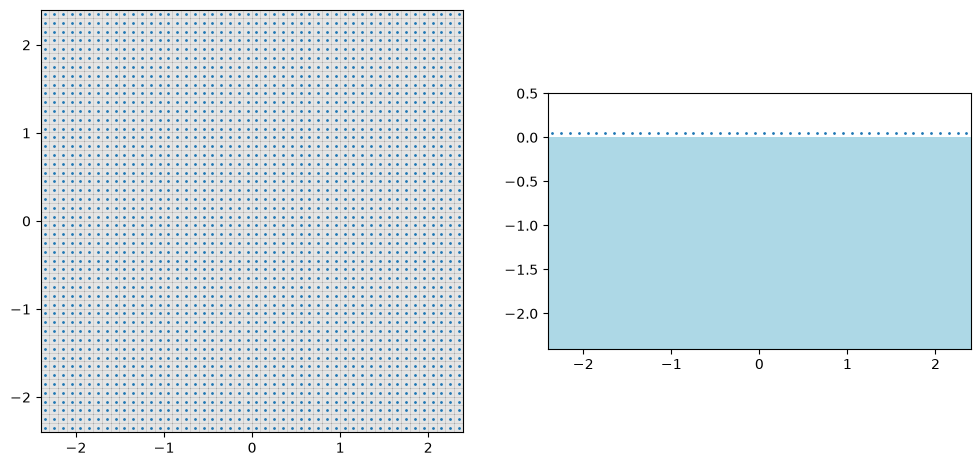

In [6]:
### Generate synthetic data ###
# Coordinate system: x positive east, y positive north, z positive upward

### Observation points: yobs, zobs ###
[xobs1, yobs1] = np.meshgrid(
    np.arange(-2.4 + 0.5*incx, 2.4, incx),
    np.arange(-2.4 + 0.5*incy, 2.4, incy)
)
xobs1 = xobs1.reshape(-1)
yobs1 = yobs1.reshape(-1)
zobs1 = 0.05 *np.ones(len(xobs1))

# Plotting
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

fig = plt.figure(figsize = (12, 6))

ax = fig.add_subplot(121)
ax.pcolor(xx2[0,:,:], yy2[0,:,:], np.zeros(xx2[0,:,:].shape), cmap = "gray", alpha = 0.1)
ax.scatter(xobs1, yobs1, s = 1)
ax.set_aspect("equal")

ax = fig.add_subplot(122)

ax.scatter(xobs1[(0<yobs1)&(yobs1<incy)], zobs1[(0<yobs1)&(yobs1<incy)], s = 1)

# Cross-section visualization
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (y_min <= 0.5*incy) & (0.5*incy <= y_max):
        
        # Block dimensions
        width  = x_max - x_min
        height = z_max - z_min

        # Draw rectangle
        rect = Rectangle((x_min, z_min), width, height,
                         facecolor="lightblue", edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.5)
ax.set_aspect("equal")

### Kernel matrix

In [7]:
from numba import njit, prange

@njit(parallel=True, fastmath=True)
def kernel_matrix2(
    exf,
    mgz,
    xobs,
    yobs,
    zobs,
    xgrd,
    ygrd,
    zgrd,
    dim,
    L
):

    nobs  = xobs.shape[0]
    ncell = xgrd.shape[0]

    xmin = np.min(xgrd)
    xmax = np.max(xgrd)

    ymin = np.min(ygrd)
    ymax = np.max(ygrd)

    K = np.zeros((nobs, ncell))

    for s in prange(ncell):

        dx1 = dim[0,0]
        dx2 = dim[0,1]

        dy1 = dim[1,0]
        dy2 = dim[1,1]

        dz1 = dim[2,0]
        dz2 = dim[2,1]

        if abs(xgrd[s] - xmin) < 1e-10:
            dx1 += L
        elif abs(xgrd[s] - xmax) < 1e-10:
            dx2 += L

        if abs(ygrd[s] - ymin) < 1e-10:
            dy1 += L
        elif abs(ygrd[s] - ymax) < 1e-10:
            dy2 += L

        dim_new = np.empty((3,2))

        dim_new[0,0] = dx1
        dim_new[0,1] = dx2

        dim_new[1,0] = dy1
        dim_new[1,1] = dy2

        dim_new[2,0] = dz1
        dim_new[2,1] = dz2

        h = magcal_numba.prism(
            mgz,
            xobs,
            yobs,
            zobs,
            xgrd[s],
            ygrd[s],
            zgrd[s],
            dim_new
        )

        K[:,s] = magcal_numba.total_force(exf, h)

        if s%1000 == 0: 
            print(s) 

    return K

In [8]:
%%time
# num of threads
from numba import set_num_threads, get_num_threads
set_num_threads(12)
print(get_num_threads())

# Unit vector creation
mgz = magcal_numba.di2xyz(dec = dec, inc = inc)
exf = mgz.copy()

# Kernel matrix
K1 = kernel_matrix2(
     exf,
     mgz,
     xobs1.astype(np.float64),
     yobs1.astype(np.float64),
     zobs1.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

12
0
37000
14000
51000
28000
5000
42000
19000
33000
10000
24000
47000
1000
38000
15000
52000
29000
6000
43000
20000
34000
11000
25000
48000
2000
39000
16000
53000
30000
7000
44000
21000
35000
12000
49000
26000
3000
40000
17000
54000
31000
8000
45000
22000
36000
13000
27000
50000
4000
41000
55000
18000
32000
9000
23000
46000
CPU times: user 5min 38s, sys: 2.88 s, total: 5min 41s
Wall time: 46.9 s


In [9]:
# Depth weighting
w1 = np.linalg.norm(K1, axis=0)
X1 = K1 / w1

### Input models

In [10]:
### Magnetization structure  ###

# ------------------------------------------------------------ #

# Time 1
beta1 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 南: block
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.4 < ygrd[k]) & (ygrd[k] < -0.6) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta1[k] = 4

# Time 2
beta2 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 南: block
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.4 < ygrd[k]) & (ygrd[k] < -0.6) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta2[k] = 3.5


# Time 3
beta3 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 北: dyke
            if (-0.1 < xgrd[k]) & (xgrd[k] < 0.1) & (0.0 < ygrd[k]) & (ygrd[k] < 1.6) & (-1.0 < zgrd[k]) & (zgrd[k] < -0.4):
                beta3[k] = -4.0
            
            # 南: block
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.4 < ygrd[k]) & (ygrd[k] < -0.6) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta3[k] = 2.5
                
# Time 4
beta4 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 北: dyke
            if (-0.1 < xgrd[k]) & (xgrd[k] < 0.1) & (0.0 < ygrd[k]) & (ygrd[k] < 1.6) & (-1.0 < zgrd[k]) & (zgrd[k] < -0.4):
                beta4[k] = -4.0        

             # 南: block
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.4 < ygrd[k]) & (ygrd[k] < -0.6) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta4[k] = 1
                
bb1 = beta1.reshape(nz, ny, nx)
bb2 = beta2.reshape(nz, ny, nx)
bb3 = beta3.reshape(nz, ny, nx)
bb4 = beta4.reshape(nz, ny, nx)

# ------------------------------------------------------------ #

# Magnetic anomaly calculation
f1_row = K1.dot(beta1)
f2_row = K1.dot(beta2)
f3_row = K1.dot(beta3)
f4_row = K1.dot(beta4)

# Centering
f1_row = f1_row - f1_row.mean()
f2_row = f2_row - f2_row.mean()
f3_row = f3_row - f3_row.mean()
f4_row = f4_row - f4_row.mean()

# Add Gaussian noise
np.random.seed(42)
noise1 = np.random.normal(loc=0, scale=5.0, size=len(f1_row))  # 5 nT
noise2 = np.random.normal(loc=0, scale=5.0, size=len(f2_row))  # 5 nT
noise3 = np.random.normal(loc=0, scale=5.0, size=len(f3_row))  # 5 nT
noise4 = np.random.normal(loc=0, scale=5.0, size=len(f4_row))  # 5 nT

fobs1 = f1_row + noise1
fobs2 = f2_row + noise2
fobs3 = f3_row + noise3
fobs4 = f4_row + noise4

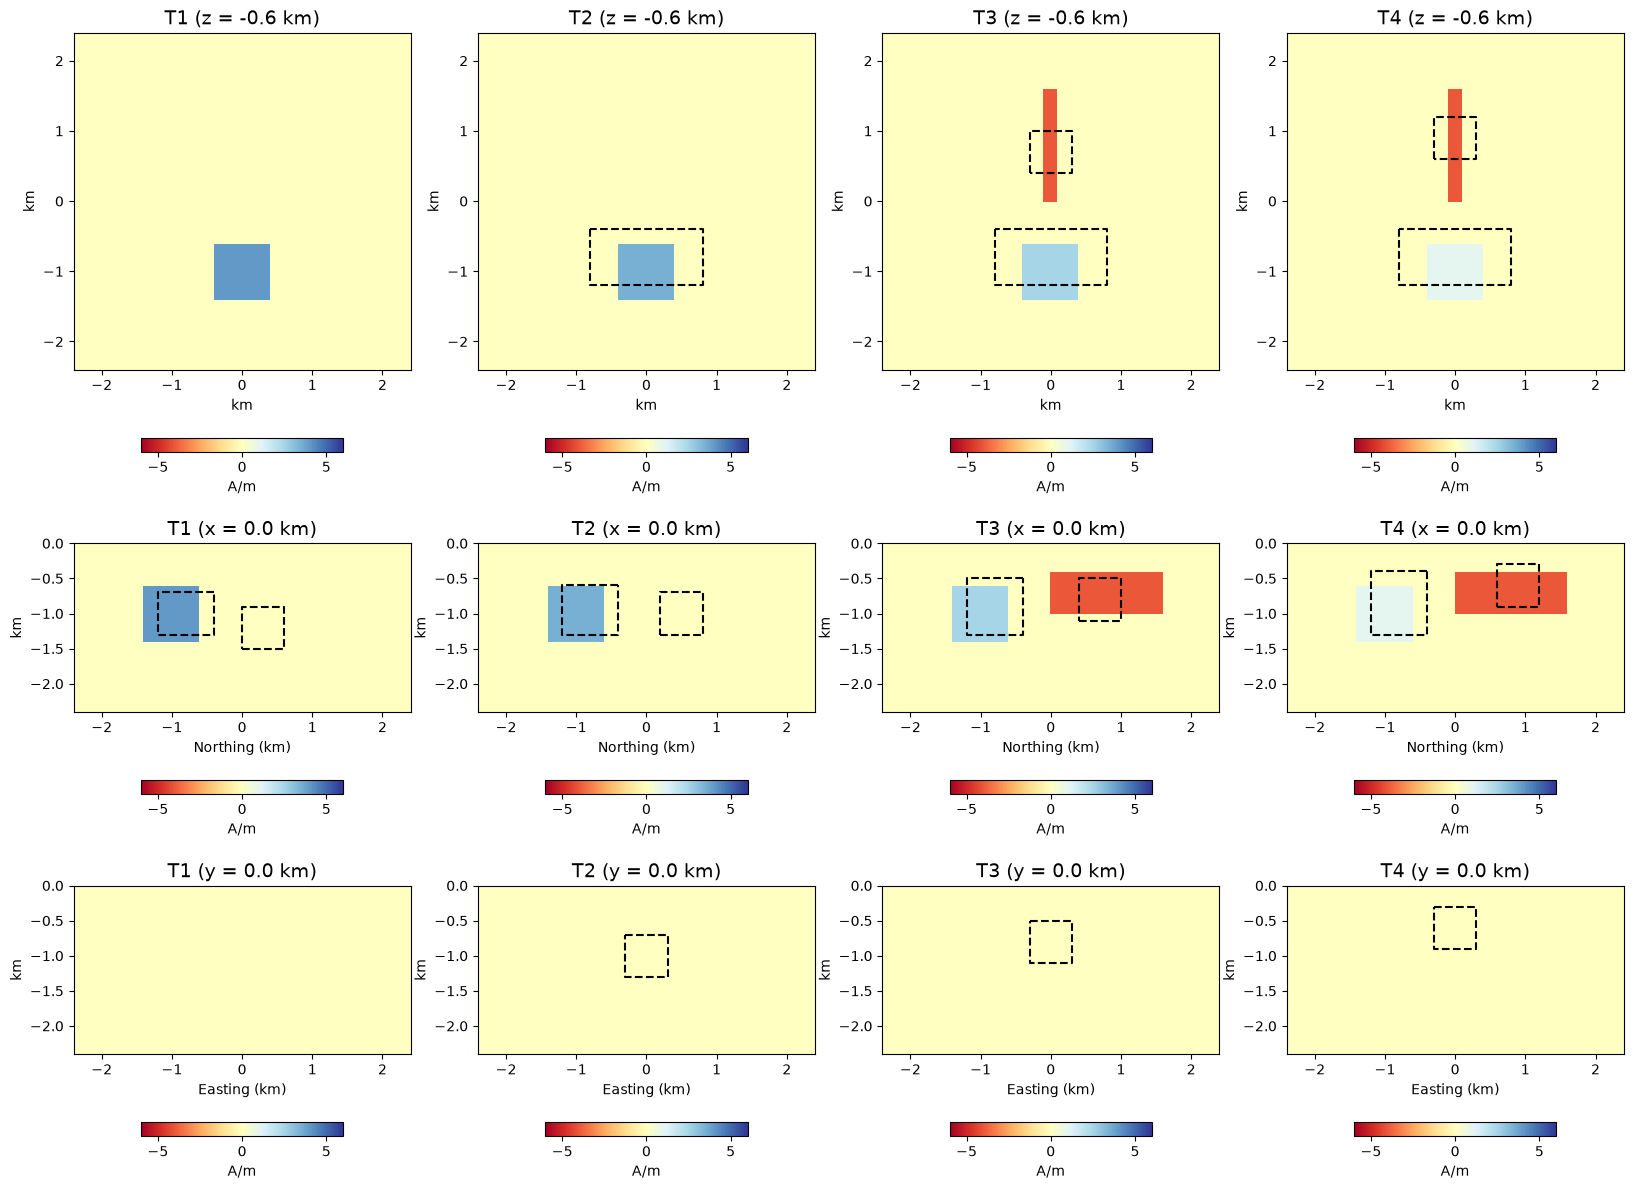

In [11]:
fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.0
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb1[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb3[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.3, -0.3, 0.3, 0.3, -0.3], [0.4, 1.0, 1.0, 0.4, 0.4], "--", color = "k")
ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(344)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb4[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.3, -0.3, 0.3, 0.3, -0.3], [0.6, 1.2, 1.2, 0.6, 0.6], "--", color = "k")
ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb1[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.0, 0.6, 0.6, 0.0, 0.0], [-1.5, -1.5, -0.9, -0.9, -1.5], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.7, -0.7, -1.3, -1.3, -0.7], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.2, 0.8, 0.8, 0.2, 0.2], [-1.3, -1.3, -0.7, -0.7, -1.3], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.6, -0.6, -1.3, -1.3, -0.6], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb3[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.4, 1.0, 1.0, 0.4, 0.4], [-1.1, -1.1, -0.5, -0.5, -1.1], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.5, -0.5, -1.3, -1.3, -0.5], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(348)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb4[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.6, 1.2, 1.2, 0.6, 0.6], [-0.9, -0.9, -0.3, -0.3, -0.9], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.4, -0.4, -1.3, -1.3, -0.4], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb1[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.3, 0.3, 0.3, -0.3, -0.3], [-0.7, -0.7, -1.3, -1.3, -0.7], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb3[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.3, 0.3, 0.3, -0.3, -0.3], [-0.5, -0.5, -1.1, -1.1, -0.5], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)


ax = fig.add_subplot(3,4,12)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb4[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.3, 0.3, 0.3, -0.3, -0.3], [-0.3, -0.3, -0.9, -0.9, -0.3], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

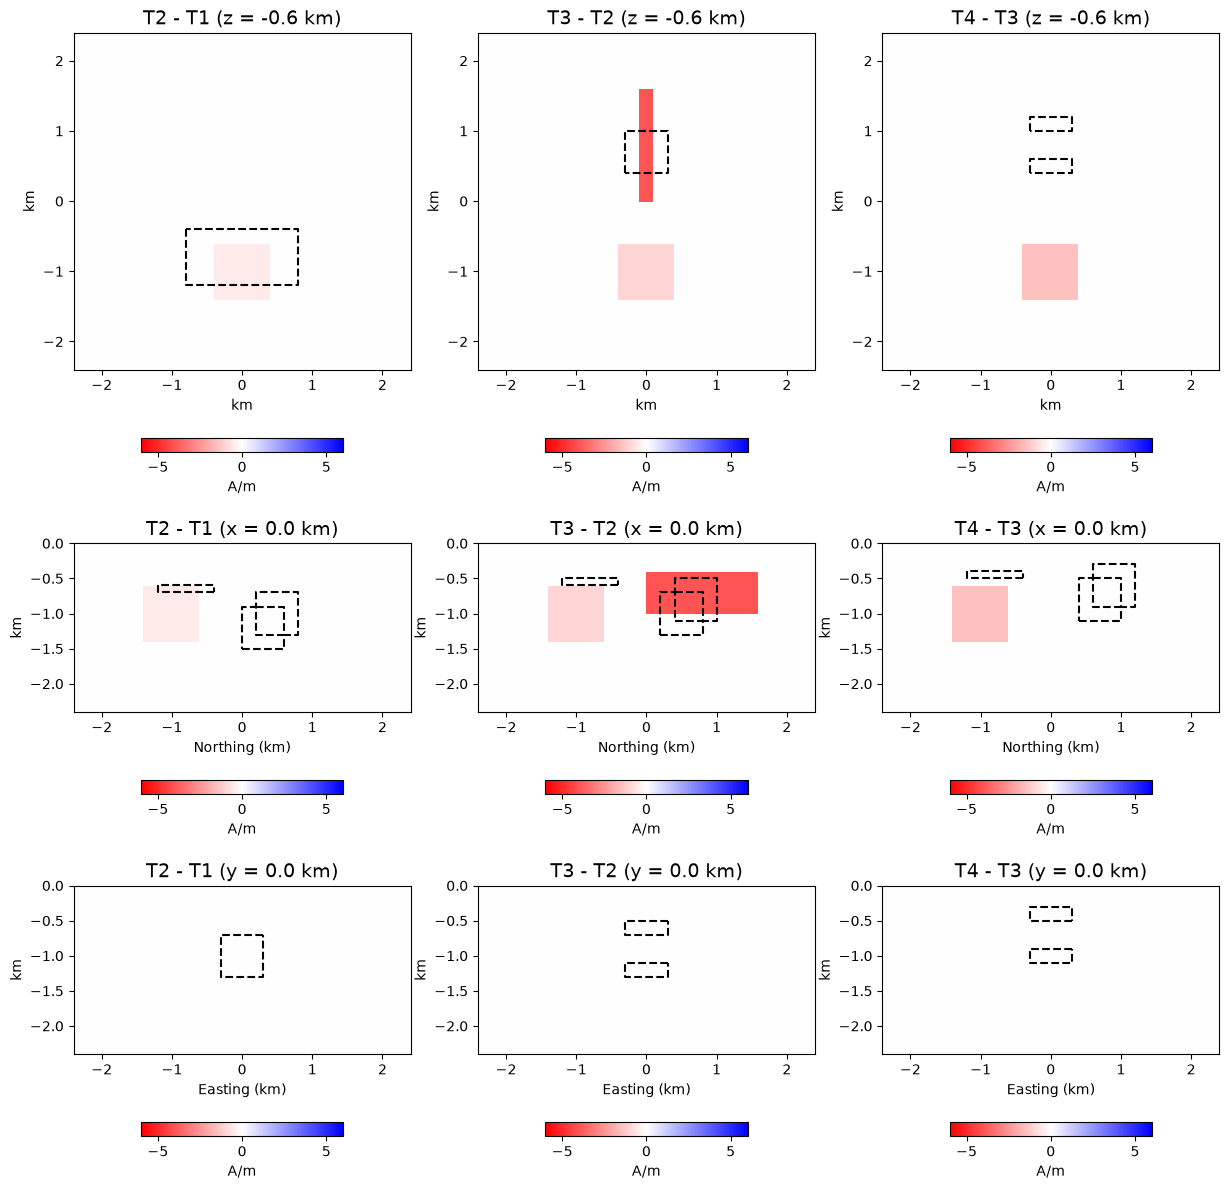

In [12]:
fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.0
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (bb2 - bb1)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (bb3 - bb2)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.3, -0.3, 0.3, 0.3, -0.3], [0.4, 1.0, 1.0, 0.4, 0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (bb4 - bb3)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.3, -0.3, 0.3, 0.3, -0.3], [0.4, 0.6, 0.6, 0.4, 0.4], "--", color = "k")
ax.plot([-0.3, -0.3, 0.3, 0.3, -0.3], [1.0, 1.2, 1.2, 1.0, 1.0], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)


ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (bb2 - bb1)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.0, 0.6, 0.6, 0.2, 0.2, 0.0, 0.0], [-1.5, -1.5, -1.3, -1.3, -0.9, -0.9, -1.5], "--", color = "k")
ax.plot([0.2, 0.6, 0.6, 0.8, 0.8, 0.2, 0.2], [-0.9, -0.9, -1.3, -1.3, -0.7, -0.7, -0.9], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.7, -0.7, -0.6, -0.6, -0.7], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (bb3 - bb2)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.2, 0.8, 0.8, 0.4, 0.4, 0.2, 0.2], [-1.3, -1.3, -1.1, -1.1, -0.7, -0.7, -1.3], "--", color = "k")
ax.plot([0.4, 0.8, 0.8, 1.0, 1.0, 0.4, 0.4], [-0.7, -0.7, -1.1, -1.1, -0.5, -0.5, -0.7], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.6, -0.6, -0.5, -0.5, -0.6], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (bb4 - bb3)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.4, 1.0, 1.0, 0.6, 0.6, 0.4, 0.4], [-1.1, -1.1, -0.9, -0.9, -0.5, -0.5, -1.1], "--", color = "k")
ax.plot([0.6, 1.0, 1.0, 1.2, 1.2, 0.6, 0.6], [-0.5, -0.5, -0.9, -0.9, -0.3, -0.3, -0.5], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.5, -0.5, -0.4, -0.4, -0.5], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (bb2 - bb1)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.3, -0.3, -0.3, 0.3, 0.3], [-0.7, -0.7, -1.3, -1.3, -0.7], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (bb3 - bb2)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.3, -0.3, -0.3, 0.3, 0.3], [-1.1, -1.1, -1.3, -1.3, -1.1], "--", color = "k")
ax.plot([0.3, -0.3, -0.3, 0.3, 0.3], [-0.5, -0.5, -0.7, -0.7, -0.5], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (bb4 - bb3)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.3, -0.3, -0.3, 0.3, 0.3], [-0.9, -0.9, -1.1, -1.1, -0.9], "--", color = "k")
ax.plot([0.3, -0.3, -0.3, 0.3, 0.3], [-0.5, -0.5, -0.3, -0.3, -0.5], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

### Joint Inversion

In [14]:
# Z
Z = np.r_[np.c_[X1, np.zeros(X1.shape), np.zeros(X1.shape), np.zeros(X1.shape)], 
          np.c_[np.zeros(X1.shape), X1, np.zeros(X1.shape), np.zeros(X1.shape)], 
          np.c_[np.zeros(X1.shape), np.zeros(X1.shape), X1, np.zeros(X1.shape)], 
          np.c_[np.zeros(X1.shape), np.zeros(X1.shape), np.zeros(X1.shape), X1]]

# f
fobs = np.r_[fobs1, fobs2, fobs3, fobs4]

# D
zeros = sp.sparse.diags(np.zeros(len(xgrd)))
D = sp.sparse.vstack([ sp.sparse.hstack([-sp.sparse.diags(1 / w1), sp.sparse.diags(1 / w1), zeros, zeros]), 
                       sp.sparse.hstack([zeros, -sp.sparse.diags(1 / w1), sp.sparse.diags(1 / w1), zeros]),
                       sp.sparse.hstack([zeros, zeros, -sp.sparse.diags(1 / w1), sp.sparse.diags(1 / w1)]),
                     ])

# Sensitivity parameter
sw = w1.copy()

print(Z.shape, fobs.shape, D.shape, sw.shape)

(9216, 221184) (9216,) (165888, 221184) (55296,)


In [16]:
%%time
# parameter
rho = 1.0
eta = 1.0

# inverse matrix
#inv1 = sp.sparse.linalg.inv(rho * sp.sparse.eye(Z.shape[1]) + eta * D.T @ D)
#inv2 = np.linalg.inv(np.eye(Z.shape[0]) + Z.dot(inv1 @ Z.T))

import pickle
with open('0921_inv1.pickle', 'rb') as f:
    inv1 = pickle.load(f)
with open('0921_inv2.pickle', 'rb') as f:
    inv2 = pickle.load(f)

CPU times: user 3.8 ms, sys: 411 ms, total: 415 ms
Wall time: 413 ms


### Step1

In [17]:
# hyper-parameters
lams_s = np.power(10., np.arange(0.5, 2.6, 0.25))
print("lams_s = {}".format(lams_s))

lam_t = 1.0  # fixed

lams_s = [  3.16227766   5.62341325  10.          17.7827941   31.6227766
  56.23413252 100.         177.827941   316.22776602]


In [18]:
# L1-L2 ratio
alpha = 0.9

In [19]:
%%time
params_all = []
betas1_all = []
betas2_all = []
betas3_all = []
betas4_all = []

for lis in range(len(lams_s)):

    params_all.append([lams_s[lis], lam_t])
    print("lm1 = {}, lm2 = {}".format(lams_s[lis], lam_t))

    model = ADMMGroupLasso(lambda_s = lams_s[lis], 
                           lambda_t = lam_t, 
                           alpha = alpha, 
                           rho = rho, 
                           eta = eta, 
                           tol = 1e-3)
    model.fit(fobs, 
              Z, 
              D, 
              sw, 
              inv1, 
              inv2, 
              times = 4, 
              num_of_cells = nx*ny*nz
             )
    
    beta_sim1 = model.beta_[0*nx*ny*nz:1*nx*ny*nz] / w1
    beta_sim2 = model.beta_[1*nx*ny*nz:2*nx*ny*nz] / w1
    beta_sim3 = model.beta_[2*nx*ny*nz:3*nx*ny*nz] / w1
    beta_sim4 = model.beta_[3*nx*ny*nz:4*nx*ny*nz] / w1

    betas1_all.append(beta_sim1)
    betas2_all.append(beta_sim2)
    betas3_all.append(beta_sim3)
    betas4_all.append(beta_sim4)

# ndarry
params_all = np.array(params_all)
betas1_all = np.array(betas1_all)
betas2_all = np.array(betas2_all)
betas3_all = np.array(betas3_all)
betas4_all = np.array(betas4_all)

lm1 = 3.1622776601683795, lm2 = 1.0
iter = 0, delta_s = 0.49367024828741013, delta_t = 0.09008789844905209, delta = 0.49367024828741013
iter = 1000, delta_s = 0.00014294468028961925, delta_t = 0.00422011880579839, delta = 0.00422011880579839
iter = 2000, delta_s = 5.7141722663691726e-05, delta_t = 0.0028042055640563955, delta = 0.0028042055640563955
iter = 3000, delta_s = 3.2753186654853774e-05, delta_t = 0.0017829320678526, delta = 0.0017829320678526
iter = 4000, delta_s = 2.088188698353666e-05, delta_t = 0.001198402902131782, delta = 0.001198402902131782
Converged at iteration 4579
lm1 = 5.623413251903491, lm2 = 1.0
iter = 0, delta_s = 0.5241783185477527, delta_t = 0.09008789844905209, delta = 0.5241783185477527
iter = 1000, delta_s = 0.0003474885462112189, delta_t = 0.0024156176705025074, delta = 0.0024156176705025074
iter = 2000, delta_s = 9.270638106161881e-05, delta_t = 0.0019128871010463822, delta = 0.0019128871010463822
iter = 3000, delta_s = 4.3070597575283174e-05, delta_t = 0

In [20]:
import pickle
with open('1004_Params_model_C_new_4d-1.pickle', 'wb') as f:
    pickle.dump(params_all, f)
with open('1004_Betas1_model_C_new_4d-1.pickle', 'wb') as f:
    pickle.dump(betas1_all, f)
with open('1004_Betas2_model_C_new_4d-1.pickle', 'wb') as f:
    pickle.dump(betas2_all, f)
with open('1004_Betas3_model_C_new_4d-1.pickle', 'wb') as f:
    pickle.dump(betas3_all, f)
with open('1004_Betas4_model_C_new_4d-1.pickle', 'wb') as f:
    pickle.dump(betas4_all, f)

In [21]:
# L-curve
rss2_1 = []
nrm2_1 = []

for lis in range(len(lams_s)):
    
    betas_temp = np.r_[betas1_all[lis]*w1, betas2_all[lis]*w1, betas3_all[lis]*w1, betas4_all[lis]*w1]
    rss_temp = misfit(fobs, Z, betas_temp)
    pen_temp = pen1(betas_temp, alpha = alpha)
    
    rss2_1.append(rss_temp)
    nrm2_1.append(pen_temp)

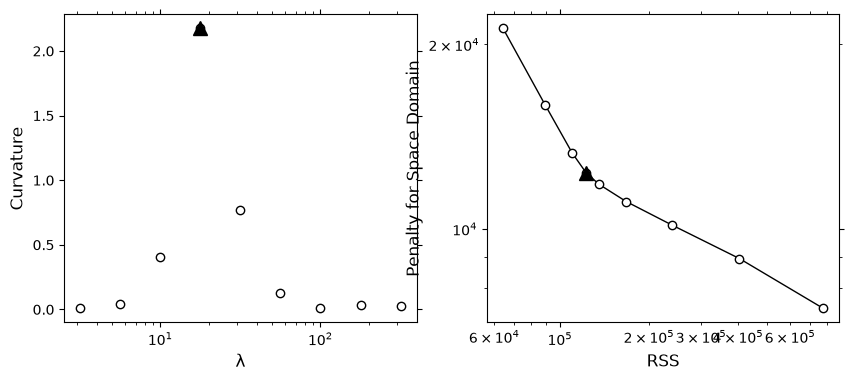

In [22]:
# curvature
fig = plt.figure(figsize = (10, 4))

ax = fig.add_subplot(121)
ax.semilogx(lams_s, calcCurvature2(np.log(rss2_1), np.log(nrm2_1)), "o", ms=6, color='#000000',markerfacecolor='#ffffff', linewidth = 1)

num_opt_1 = np.argmax(calcCurvature2(np.log(rss2_1), np.log(nrm2_1)))

ax.semilogx(lams_s[num_opt_1], calcCurvature2(np.log(rss2_1), np.log(nrm2_1))[num_opt_1], '^', ms=10, color = "black")
ax.set_xlabel(r'${\rm \lambda}$', fontsize = 12)
ax.set_ylabel(r'${\rm Curvature}$', fontsize = 12)

ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
ax.ticklabel_format(style="sci",  axis="y", scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.5, 6.5)

ax = fig.add_subplot(122)
ax.loglog(rss2_1, nrm2_1, 'o-', ms=6, color='#000000', markerfacecolor='#ffffff', linewidth = 1)
ax.loglog(rss2_1[num_opt_1], nrm2_1[num_opt_1], '^', ms=10, color = "black")
ax.set_xlabel(r'$\text{RSS}$', fontsize = 12)
ax.set_ylabel(r'$\text{Penalty for Space Domain}$', fontsize = 12)
#ax.set_xlim(1e3, 13e4)
#ax.set_ylim(2e3, 3e4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

plt.subplots_adjust(hspace=0.6)

In [23]:
print("optimal lambda_s = {:.2f}".format(lams_s[num_opt_1]))

optimal lambda_s = 17.78


### Step.2

In [24]:
# hyper-parameters
lams_t = np.power(10., np.arange(0.0, 2.1, 0.25))
print("lams_t = {}".format(lams_t))

lams_t = [  1.           1.77827941   3.16227766   5.62341325  10.
  17.7827941   31.6227766   56.23413252 100.        ]


In [25]:
%%time
params_all = []
betas1_all = []
betas2_all = []
betas3_all = []
betas4_all = []

for lit in range(len(lams_t)):

    params_all.append([lams_s[num_opt_1], lams_t[lit]])
    print("lm1 = {:.3f}, lm2 = {:.3f}".format(lams_s[num_opt_1], lams_t[lit]))

    model = ADMMGroupLasso(lambda_s = lams_s[num_opt_1], 
                           lambda_t = lams_t[lit], 
                           alpha = alpha, 
                           rho = rho, 
                           eta = eta, 
                           tol = 1e-3
                          )
    model.fit(fobs, 
              Z, 
              D, 
              sw, 
              inv1, 
              inv2, 
              times = 4, 
              num_of_cells = nx*ny*nz
             )
    
    beta_sim1 = model.beta_[0*nx*ny*nz:1*nx*ny*nz] / w1
    beta_sim2 = model.beta_[1*nx*ny*nz:2*nx*ny*nz] / w1
    beta_sim3 = model.beta_[2*nx*ny*nz:3*nx*ny*nz] / w1
    beta_sim4 = model.beta_[3*nx*ny*nz:4*nx*ny*nz] / w1

    betas1_all.append(beta_sim1)
    betas2_all.append(beta_sim2)
    betas3_all.append(beta_sim3)
    betas4_all.append(beta_sim4)

# ndarry
params_all = np.array(params_all)
betas1_all = np.array(betas1_all)
betas2_all = np.array(betas2_all)
betas3_all = np.array(betas3_all)
betas4_all = np.array(betas4_all)

lm1 = 17.783, lm2 = 1.000
iter = 0, delta_s = 0.5259005102509811, delta_t = 0.09008789844905209, delta = 0.5259005102509811
iter = 1000, delta_s = 0.0016388233558746034, delta_t = 0.00041794250895317114, delta = 0.0016388233558746034
Converged at iteration 1568
lm1 = 17.783, lm2 = 1.778
iter = 0, delta_s = 0.5259005102509811, delta_t = 0.09024460203745202, delta = 0.5259005102509811
iter = 1000, delta_s = 0.0015966471400628323, delta_t = 0.000505714563931434, delta = 0.0015966471400628323
Converged at iteration 1545
lm1 = 17.783, lm2 = 3.162
iter = 0, delta_s = 0.5259005102509811, delta_t = 0.09024460203745202, delta = 0.5259005102509811
iter = 1000, delta_s = 0.0015506048514775971, delta_t = 0.0006850361473422727, delta = 0.0015506048514775971
Converged at iteration 1508
lm1 = 17.783, lm2 = 5.623
iter = 0, delta_s = 0.5259005102509811, delta_t = 0.09024460203745202, delta = 0.5259005102509811
iter = 1000, delta_s = 0.0016032635357603768, delta_t = 0.0013274135462062412, delta = 0.0016

In [26]:
import pickle
with open('1004_Params_model_C_new_4d-2.pickle', 'wb') as f:
    pickle.dump(params_all, f)
with open('1004_Betas1_model_C_new_4d-2.pickle', 'wb') as f:
    pickle.dump(betas1_all, f)
with open('1004_Betas2_model_C_new_4d-2.pickle', 'wb') as f:
    pickle.dump(betas2_all, f)
with open('1004_Betas3_model_C_new_4d-2.pickle', 'wb') as f:
    pickle.dump(betas3_all, f)
with open('1004_Betas4_model_C_new_4d-2.pickle', 'wb') as f:
    pickle.dump(betas4_all, f)

In [27]:
# L-curve
rss2_2 = []
nrm2_2 = []

for lit in range(len(lams_t)):
    
    betas_temp = np.r_[betas1_all[lit]*w1, betas2_all[lit]*w1, betas3_all[lit]*w1, betas4_all[lit]*w1]
    rss_temp = misfit(fobs, Z, betas_temp)
    pen_temp = pen2(D @ betas_temp, sw, nx*ny*nz, 4)

    print(rss_temp, pen_temp)
    
    rss2_2.append(rss_temp)
    nrm2_2.append(pen_temp)

122548.2826089079 3680.268319924712
122780.88710034968 3620.471128673927
123132.16823171535 3562.7682729908606
123655.84310921055 3511.180749894965
124690.48281408718 3430.380539983662
126668.41043557422 3305.610683464224
130772.4862142787 3150.9790576686823
140166.28560211495 2967.9171928567994
162054.32421607585 2739.1631417409426


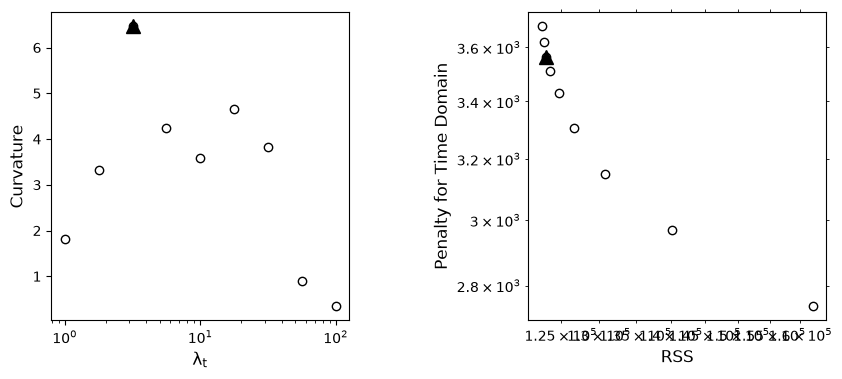

In [35]:
# curvature
fig = plt.figure(figsize = (10, 4))

ax = fig.add_subplot(121)
ax.semilogx(lams_t, calcCurvature2(np.log(rss2_2), np.log(nrm2_2)), 
            "o", ms=6, color='k',markerfacecolor='#ffffff', linewidth = 1)

num_opt_2 = np.argmax(calcCurvature2(np.log(rss2_2), np.log(nrm2_2)))

ax.semilogx(lams_t[num_opt_2], 
            calcCurvature2(np.log(rss2_2), np.log(nrm2_2))[num_opt_2], 
            '^', ms=10, color = "black")
ax.set_xlabel(r'${\rm \lambda_t}$', fontsize = 12)
ax.set_ylabel(r'${\rm Curvature}$', fontsize = 12)

#ax.xaxis.set_ticks_position('both')
#ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
ax.ticklabel_format(style="sci",  axis="y",scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.1, 0.65)

ax = fig.add_subplot(122)
ax.loglog(rss2_2, nrm2_2, 'o', ms=6, color='k', markerfacecolor='#ffffff', linewidth = 1)

ax.loglog(rss2_2[num_opt_2], 
          nrm2_2[num_opt_2], 
          '^', ms=10, color = "black")

ax.set_xlabel(r'$\text{RSS}$', fontsize = 12)
ax.set_ylabel(r'$\text{Penalty for Time Domain}$', fontsize = 12)
#ax.set_xlim(3.16e4, 3.23e4)
#ax.set_ylim(6e1, 5e2)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

#ax.set_aspect("equal")

plt.subplots_adjust(wspace=0.6)

In [36]:
print("optimal lambda_t = {}".format(lams_t[num_opt_2]))

optimal lambda_t = 3.1622776601683795


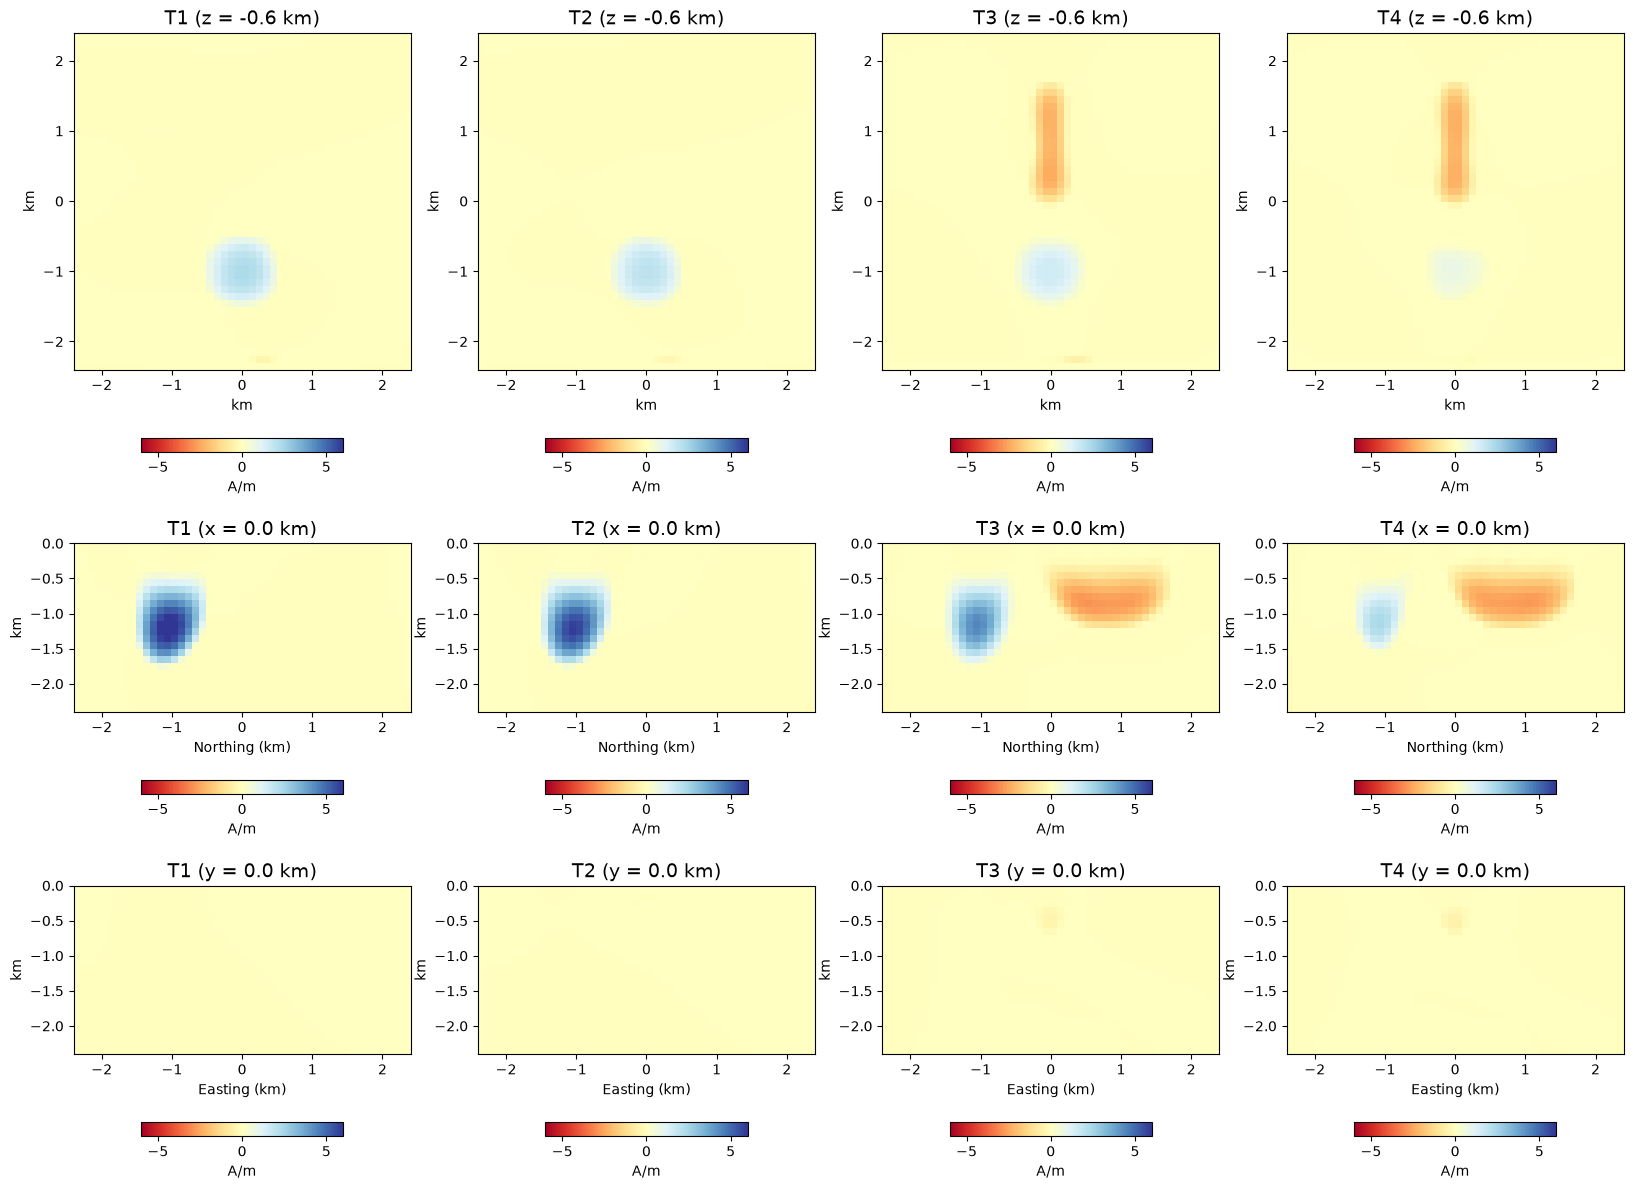

In [37]:
fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.0
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(344)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas4_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(348)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas4_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)


ax = fig.add_subplot(3,4,12)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas4_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

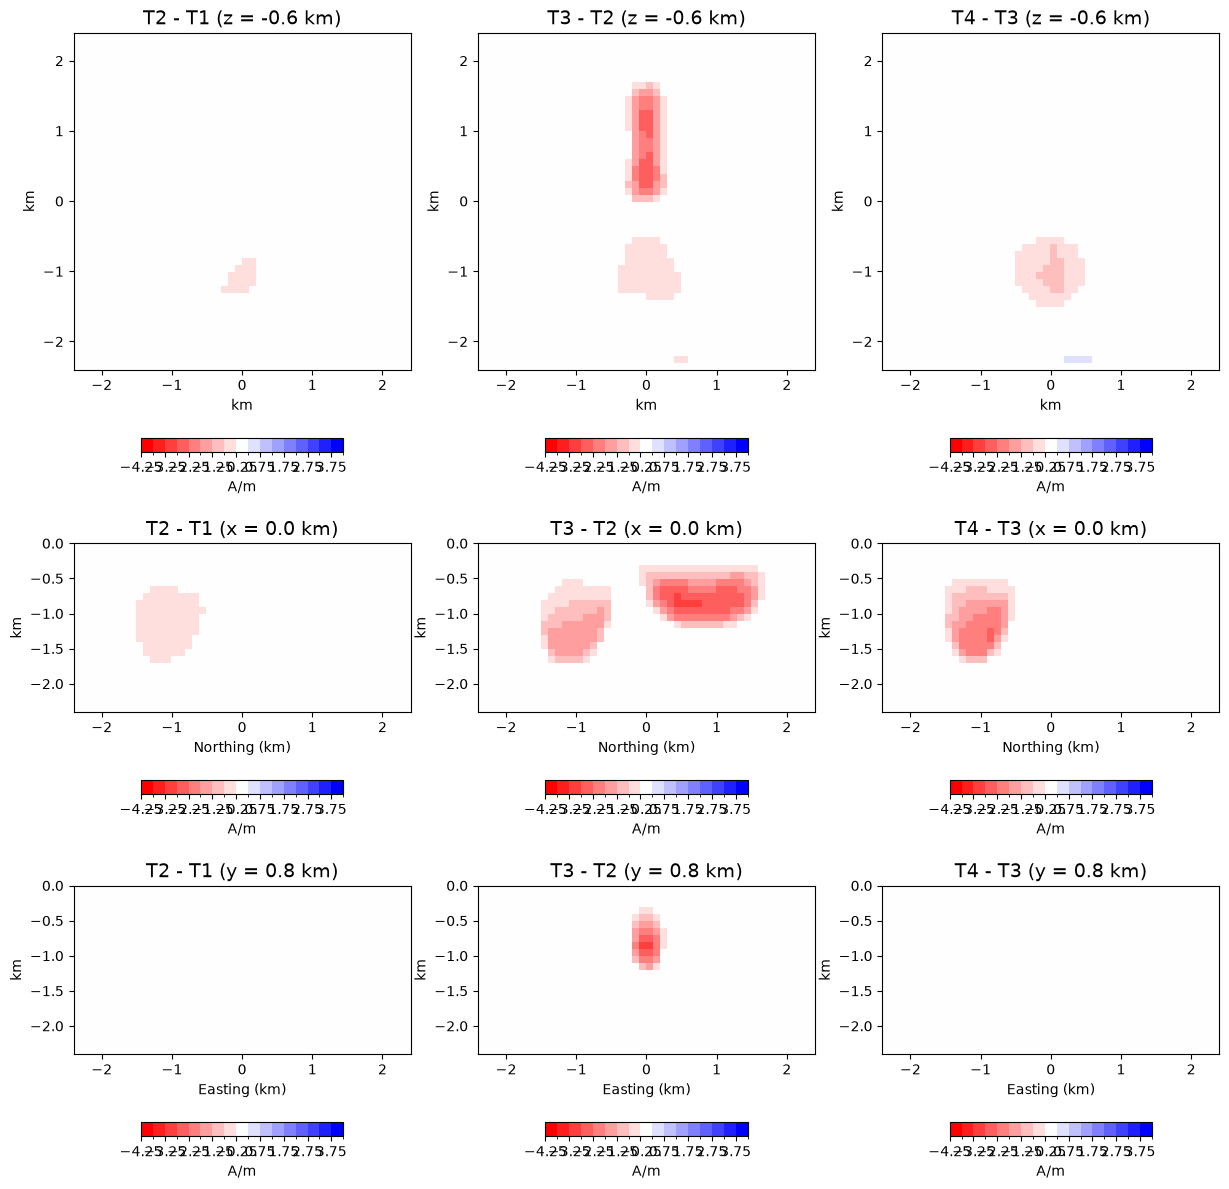

In [38]:
from matplotlib.colors import BoundaryNorm
bounds = np.arange(-4.25, 4.26, 0.5)
cmap = plt.get_cmap("bwr_r")
norm = BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.8
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas2_all[num_opt_2] - betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas3_all[num_opt_2] - betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas4_all[num_opt_2] - betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas2_all[num_opt_2] - betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas3_all[num_opt_2] - betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas4_all[num_opt_2] - betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)


ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas2_all[num_opt_2] - betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas3_all[num_opt_2] - betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas4_all[num_opt_2] - betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

### Step.3

In [39]:
# hyper-parameters
lams_s = np.power(10., np.arange(0.5, 2.6, 0.25))
print("lams_s = {}".format(lams_s))

lams_s = [  3.16227766   5.62341325  10.          17.7827941   31.6227766
  56.23413252 100.         177.827941   316.22776602]


In [40]:
%%time
params_all = []
betas1_all = []
betas2_all = []
betas3_all = []
betas4_all = []

for lis in range(len(lams_s)):

    params_all.append([lams_s[lis], lams_t[num_opt_2]])
    print("lm1 = {:.2f}, lm2 = {:.2f}".format(lams_s[lis], lams_t[num_opt_2]))

    model = ADMMGroupLasso(lambda_s = lams_s[lis], 
                           lambda_t = lams_t[num_opt_2], 
                           alpha = alpha, 
                           rho = rho, 
                           eta = eta, 
                           tol = 1e-3)
    model.fit(fobs, 
              Z, 
              D, 
              sw, 
              inv1, 
              inv2, 
              times = 4, 
              num_of_cells = nx*ny*nz
             )
    
    beta_sim1 = model.beta_[0*nx*ny*nz:1*nx*ny*nz] / w1
    beta_sim2 = model.beta_[1*nx*ny*nz:2*nx*ny*nz] / w1
    beta_sim3 = model.beta_[2*nx*ny*nz:3*nx*ny*nz] / w1
    beta_sim4 = model.beta_[3*nx*ny*nz:4*nx*ny*nz] / w1

    betas1_all.append(beta_sim1)
    betas2_all.append(beta_sim2)
    betas3_all.append(beta_sim3)
    betas4_all.append(beta_sim4)

# ndarry
params_all = np.array(params_all)
betas1_all = np.array(betas1_all)
betas2_all = np.array(betas2_all)
betas3_all = np.array(betas3_all)
betas4_all = np.array(betas4_all)

lm1 = 3.16, lm2 = 3.16
iter = 0, delta_s = 0.49367024828741013, delta_t = 0.09024460203745202, delta = 0.49367024828741013
iter = 1000, delta_s = 0.00019687515924273112, delta_t = 0.004624125312286188, delta = 0.004624125312286188
iter = 2000, delta_s = 9.360743417638382e-05, delta_t = 0.00396611786466732, delta = 0.00396611786466732
iter = 3000, delta_s = 6.628231188196908e-05, delta_t = 0.003498824441944446, delta = 0.003498824441944446
iter = 4000, delta_s = 5.4578557324578785e-05, delta_t = 0.0030647606688707233, delta = 0.0030647606688707233
iter = 5000, delta_s = 4.5403993365904676e-05, delta_t = 0.0026671044235984168, delta = 0.0026671044235984168
iter = 6000, delta_s = 4.005980770449053e-05, delta_t = 0.0023436293442422188, delta = 0.0023436293442422188
iter = 7000, delta_s = 3.601090905937866e-05, delta_t = 0.002041266555853075, delta = 0.002041266555853075
iter = 8000, delta_s = 3.090754671028166e-05, delta_t = 0.0017845883145881007, delta = 0.0017845883145881007
iter = 9000,

In [41]:
import pickle
with open('1004_Params_model_C_new_4d-3.pickle', 'wb') as f:
    pickle.dump(params_all, f)
with open('1004_Betas1_model_C_new_4d-3.pickle', 'wb') as f:
    pickle.dump(betas1_all, f)
with open('1004_Betas2_model_C_new_4d-3.pickle', 'wb') as f:
    pickle.dump(betas2_all, f)
with open('1004_Betas3_model_C_new_4d-3.pickle', 'wb') as f:
    pickle.dump(betas3_all, f)
with open('1004_Betas4_model_C_new_4d-3.pickle', 'wb') as f:
    pickle.dump(betas4_all, f)

In [43]:
# L-curve
rss2_3 = []
nrm2_3 = []

for lis in range(len(lams_s)):
    
    betas_temp = np.r_[betas1_all[lis]*w1, betas2_all[lis]*w1, betas3_all[lis]*w1, betas4_all[lis]*w1]
    rss_temp = misfit(fobs, Z, betas_temp)
    pen_temp = pen1(betas_temp, alpha = alpha)
    
    rss2_3.append(rss_temp)
    nrm2_3.append(pen_temp)

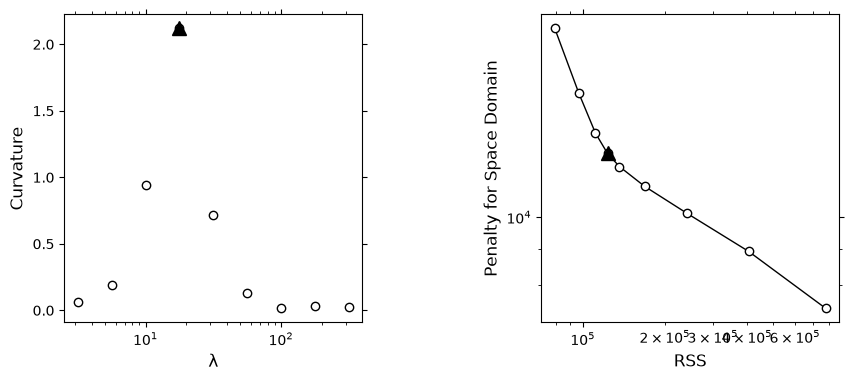

In [44]:
# curvature
fig = plt.figure(figsize = (10, 4))

ax = fig.add_subplot(121)
ax.semilogx(lams_s, calcCurvature2(np.log(rss2_3), np.log(nrm2_3)), "o", ms=6, color='#000000',markerfacecolor='#ffffff', linewidth = 1)

num_opt_3 = np.argmax(calcCurvature2(np.log(rss2_3), np.log(nrm2_3)))

ax.semilogx(lams_s[num_opt_3], calcCurvature2(np.log(rss2_3), np.log(nrm2_3))[num_opt_3], '^', ms=10, color = "black")
ax.set_xlabel(r'${\rm \lambda}$', fontsize = 12)
ax.set_ylabel(r'${\rm Curvature}$', fontsize = 12)

ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
ax.ticklabel_format(style="sci",  axis="y", scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.5, 6.5)

ax = fig.add_subplot(122)
ax.loglog(rss2_3, nrm2_3, 'o-', ms=6, color='#000000', markerfacecolor='#ffffff', linewidth = 1)
ax.loglog(rss2_3[num_opt_3], nrm2_3[num_opt_3], '^', ms=10, color = "black")
ax.set_xlabel(r'$\text{RSS}$', fontsize = 12)
ax.set_ylabel(r'$\text{Penalty for Space Domain}$', fontsize = 12)
#ax.set_xlim(1e3, 13e4)
#ax.set_ylim(2e3, 3e4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

plt.subplots_adjust(wspace=0.6)

In [45]:
print("optimal lambda_s = {}".format(lams_s[num_opt_3]))

optimal lambda_s = 17.78279410038923
